In [5]:
import pandas as pd
import yfinance as yf
import numpy as np
import time
import random
from datetime import timedelta
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import LabelEncoder
import warnings

warnings.filterwarnings('ignore')

# Carga de datos
df = pd.read_csv('../2020-2025PP.csv') 

# Normalización de fechas
df['Buy_Date'] = pd.to_datetime(df['Notif_Date'], errors='coerce').dt.tz_localize(None)
df['Sell_Date'] = df['Buy_Date'] + timedelta(days=19)
df['Mes_Operacion'] = df['Buy_Date'].dt.month

In [6]:
# Extracción de precios y cálculo de rendimiento relativo (ventana de 19 días)
tickers = df['Acronym'].dropna().unique().tolist()
if 'SPY' not in tickers:
    tickers.append('SPY')

hist_data_dict = {}

# Descarga secuencial con manejo de rate-limiting de la API
for i, ticker in enumerate(tickers):
    intentos = 0
    while intentos < 3:
        try:
            temp = yf.download(ticker, start="2019-01-01", progress=False, auto_adjust=True)
            if not temp.empty:
                if isinstance(temp.columns, pd.MultiIndex):
                    hist_data_dict[ticker] = temp['Close'][ticker]
                else:
                    hist_data_dict[ticker] = temp['Close']
            break 
        except Exception:
            intentos += 1
            time.sleep(2)
            
    time.sleep(random.uniform(0.1, 0.4))

hist_data = pd.DataFrame(hist_data_dict)

def get_price(ticker, target_date, method='forward'):
    """
    Obtiene el precio de cierre más cercano a la fecha indicada.
    Utiliza 'bfill' (forward) para asegurar que el precio de compra sea posterior a la notificación,
    y 'nearest' para el cierre de la posición.
    """
    if ticker not in hist_data.columns: return np.nan
    series = hist_data[ticker].dropna()
    if series.empty: return np.nan
    
    try:
        idx = series.index.get_indexer([target_date], method='bfill' if method=='forward' else 'nearest')[0]
        if idx != -1 and idx < len(series): 
            return series.iloc[idx]
    except: 
        return np.nan
    return np.nan

# Cálculo del rendimiento de la operación frente al benchmark (SPY)
df['Buy_Price'] = df.apply(lambda row: get_price(row['Acronym'], row['Buy_Date'], 'forward'), axis=1)
df['Sell_Price'] = df.apply(lambda row: get_price(row['Acronym'], row['Sell_Date'], 'nearest'), axis=1)
df['Return_19d'] = (df['Sell_Price'] - df['Buy_Price']) / df['Buy_Price']

df['SPY_Buy'] = df['Buy_Date'].apply(lambda x: get_price('SPY', x, 'forward'))
df['SPY_Sell'] = df['Sell_Date'].apply(lambda x: get_price('SPY', x, 'nearest'))
df['Return_SPY_19d'] = (df['SPY_Sell'] - df['SPY_Buy']) / df['SPY_Buy']

$CTRL: possibly delisted; no timezone found

1 Failed download:
['CTRL']: possibly delisted; no timezone found
$NYCB: possibly delisted; no timezone found

1 Failed download:
['NYCB']: possibly delisted; no timezone found
$MNK: possibly delisted; no timezone found

1 Failed download:
['MNK']: possibly delisted; no timezone found
$SUP: possibly delisted; no timezone found

1 Failed download:
['SUP']: possibly delisted; no timezone found
$XON: possibly delisted; no timezone found

1 Failed download:
['XON']: possibly delisted; no timezone found
$BAF: possibly delisted; no timezone found

1 Failed download:
['BAF']: possibly delisted; no timezone found
$RCII: possibly delisted; no timezone found

1 Failed download:
['RCII']: possibly delisted; no timezone found
$TMHC: possibly delisted; no price data found  (1d 2019-01-01 -> 2026-11-07)

1 Failed download:
['TMHC']: possibly delisted; no price data found  (1d 2019-01-01 -> 2026-11-07)
$UMPQ: possibly delisted; no timezone found

1 Failed 

Iniciando preprocesamiento de datos...
Entrenando clasificador Random Forest...


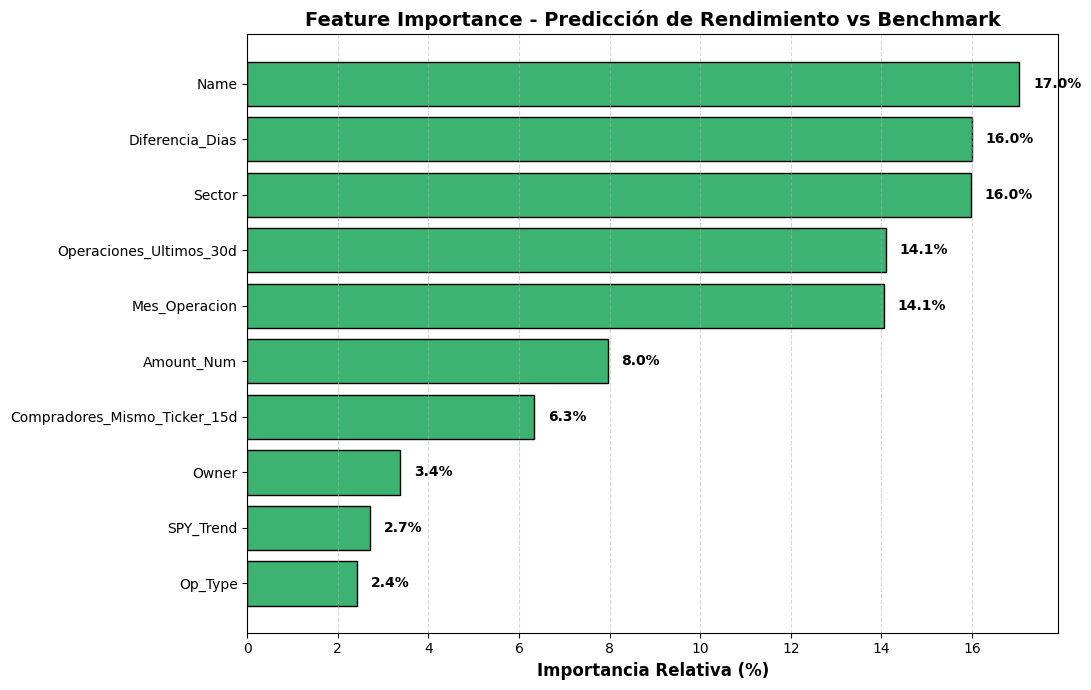


--- RESUMEN DEL DATASET VÁLIDO ---
Operaciones procesadas: 11181
Tasa base de éxito (Target = 1): 48.8%


In [7]:
# Preprocesamiento de features y definición del target
print("Iniciando preprocesamiento de datos...")

# Imputación de valores nulos estructurales
df['Owner'] = df['Owner'].fillna('Self')

columnas_necesarias = [
    'Return_19d', 'Return_SPY_19d', 'Sector', 'Amount_Num', 
    'Diferencia_Dias', 'SPY_Trend', 'Name', 'Owner', 'Op_Type',
    'Operaciones_Ultimos_30d', 'Compradores_Mismo_Ticker_15d', 'Mes_Operacion'
]
df_ml = df.dropna(subset=columnas_necesarias).copy()

# Definición de la variable objetivo (1: Supera al S&P 500, 0: Underperformance)
df_ml['Exito'] = np.where(df_ml['Return_19d'] > df_ml['Return_SPY_19d'], 1, 0)

features = [
    'Amount_Num', 'Diferencia_Dias', 'Operaciones_Ultimos_30d', 
    'Compradores_Mismo_Ticker_15d', 'SPY_Trend', 'Mes_Operacion', 
    'Sector', 'Name', 'Owner', 'Op_Type'
]
X = df_ml[features].copy()
y = df_ml['Exito']

# Encoding de variables categóricas
codificadores = {}
columnas_texto = ['Sector', 'Name', 'Owner', 'Op_Type']

for col in columnas_texto:
    le = LabelEncoder()
    X[col] = le.fit_transform(X[col].astype(str))
    codificadores[col] = le

# Entrenamiento del modelo
print("Entrenando clasificador Random Forest...")

# n_estimators alto para mayor estabilidad; max_depth=7 para prevenir overfitting
modelo_rf = RandomForestClassifier(n_estimators=1500, random_state=42, max_depth=7)
modelo_rf.fit(X, y)

# Extracción y visualización de Feature Importance
importancias = modelo_rf.feature_importances_
df_importancias = pd.DataFrame({'Variable': features, 'Importancia': importancias * 100})
df_importancias = df_importancias.sort_values('Importancia', ascending=True)

plt.figure(figsize=(11, 7))
plt.barh(df_importancias['Variable'], df_importancias['Importancia'], color='mediumseagreen', edgecolor='black')
plt.xlabel('Importancia Relativa (%)', fontsize=12, fontweight='bold')
plt.title('Feature Importance - Predicción de Rendimiento vs Benchmark', fontsize=14, fontweight='bold')
plt.grid(axis='x', linestyle='--', alpha=0.5)

for index, value in enumerate(df_importancias['Importancia']):
    plt.text(value + 0.3, index, f'{value:.1f}%', va='center', fontweight='bold')

plt.tight_layout()
plt.show()

# Resumen de validación
print("\n--- RESUMEN DEL DATASET VÁLIDO ---")
print(f"Operaciones procesadas: {len(df_ml)}")
print(f"Tasa base de éxito (Target = 1): {(y.mean() * 100):.1f}%")

In [4]:
# Análisis de direccionalidad y métricas de rendimiento por variable
import pandas as pd

df_analisis = df_ml.copy()

print("--- Top 5 Sectores por Win Rate (N >= 30) ---")
sectores = df_analisis.groupby('Sector')['Exito'].agg(['mean', 'count'])
sectores = sectores[sectores['count'] >= 30].sort_values('mean', ascending=False)
sectores['Win Rate'] = (sectores['mean'] * 100).round(1).astype(str) + '%'
print(sectores[['count', 'Win Rate']].head(5))

print("\n--- Análisis de Retraso de Reporte (Diferencia_Dias) ---")
bins = [-1, 5, 15, 30, 45, 999]
labels = ['0-5 días', '6-15 días', '16-30 días', '31-45 días', '>45 días']
df_analisis['Dias_Rango'] = pd.cut(df_analisis['Diferencia_Dias'], bins=bins, labels=labels)

retraso = df_analisis.groupby('Dias_Rango', observed=True)['Exito'].agg(['mean', 'count'])
retraso['Win Rate'] = (retraso['mean'] * 100).round(1).astype(str) + '%'
print(retraso[['count', 'Win Rate']])

print("\n--- Top 5 Perfiles Históricos (Min. 20 operaciones) ---")
senadores = df_analisis.groupby('Name')['Exito'].agg(['mean', 'count'])
senadores = senadores[senadores['count'] >= 20].sort_values('mean', ascending=False)
senadores['Win Rate'] = (senadores['mean'] * 100).round(1).astype(str) + '%'
print(senadores[['count', 'Win Rate']].head(5))

--- Top 5 Sectores por Win Rate (N >= 30) ---
                    count Win Rate
Sector                            
Basic Materials       346    53.8%
Real Estate           331    52.3%
Technology           2236    52.0%
Financial Services   1365    51.9%
Energy                765    51.2%

--- Análisis de Retraso de Reporte (Diferencia_Dias) ---
            count Win Rate
Dias_Rango                
0-5 días     3713    50.2%
6-15 días    2440    46.8%
16-30 días   3117    49.1%
31-45 días    821    47.6%
>45 días     1096    48.3%

--- Top 5 Perfiles Históricos (Min. 20 operaciones) ---
                                         count Win Rate
Name                                                   
Hon. C. Scott Franklin                      33    75.8%
Hon. David J. Taylor                        35    71.4%
Hon. John James                            118    71.2%
Hon. Donald Sternoff Honorable Beyer Jr     43    69.8%
Hon. Julie Johnson                          68    66.2%


In [8]:
# Definición y evaluación de estrategias cuantitativas (Backtesting)

# Identificación de perfiles con rendimiento superior
stats_senadores = df_analisis.groupby('Name')['Exito'].agg(['mean', 'count'])
perfiles_destacados = stats_senadores[(stats_senadores['count'] >= 20) & (stats_senadores['mean'] >= 0.58)]
top_senadores = perfiles_destacados.index.tolist()

print(f"Perfiles institucionales seleccionados (N={len(top_senadores)}):")
for senador in top_senadores:
    print(f"  - {senador} (Win Rate: {perfiles_destacados.loc[senador, 'mean']*100:.1f}%)")
print("-" * 50)

# Definición de filtros estratégicos
filtro_senadores = df_analisis['Name'].isin(top_senadores)
filtro_sectores = df_analisis['Sector'].isin(['Energy', 'Real Estate']) 
filtro_latencia = (df_analisis['Diferencia_Dias'] <= 5) | (df_analisis['Diferencia_Dias'] >= 45)

# Evaluación de estrategias aisladas y combinadas
ops_senadores = df_analisis[filtro_senadores]
wr_senadores = ops_senadores['Exito'].mean() * 100

ops_sectores = df_analisis[filtro_sectores]
wr_sectores = ops_sectores['Exito'].mean() * 100

ops_combinada = df_analisis[filtro_sectores & filtro_latencia]
wr_combinada = ops_combinada['Exito'].mean() * 100

filtro_global = filtro_senadores | (filtro_sectores & filtro_latencia)
ops_global = df_analisis[filtro_global]
wr_global = ops_global['Exito'].mean() * 100

# Resultados
print("\n========== RESULTADOS DEL BACKTEST ==========\n")
print("Baseline del Congreso: 50.4% de win rate\n")

print("Seguimiento de top performers:")
print(f" -> Operaciones: {len(ops_senadores)}")
print(f" -> Win Rate: {wr_senadores:.1f}%\n")

print("Sectores estratégicos ('Energy', 'Real Estate'):")
print(f" -> Operaciones: {len(ops_sectores)}")
print(f" -> Win Rate: {wr_sectores:.1f}%\n")

print("Sectores estratégicos + Latencia anómala (<5 o >45 días):")
print(f" -> Operaciones: {len(ops_combinada)}")
print(f" -> Win Rate: {wr_combinada:.1f}%\n")

print("Filtro Agregado:")
print(f" -> Operaciones: {len(ops_global)}")
print(f" -> Win Rate: {wr_global:.1f}%")
print("=============================================")

Perfiles institucionales seleccionados (N=12):
  - Hon. C. Scott Franklin (Win Rate: 75.8%)
  - Hon. Christopher L. Jacobs (Win Rate: 65.8%)
  - Hon. David J. Taylor (Win Rate: 71.4%)
  - Hon. Donald Sternoff Honorable Beyer Jr (Win Rate: 69.8%)
  - Hon. James Comer (Win Rate: 62.1%)
  - Hon. John James (Win Rate: 71.2%)
  - Hon. Julie Johnson (Win Rate: 66.2%)
  - Hon. Mark Dr Green (Win Rate: 61.7%)
  - Hon. Nancy Pelosi (Win Rate: 61.9%)
  - Hon. Tim Moore (Win Rate: 61.5%)
  - Hon. Victoria Spartz (Win Rate: 61.9%)
  - Mrs. Marjorie Taylor Greene (Win Rate: 59.1%)
--------------------------------------------------

========== RESULTADOS DEL BACKTEST ==========

Baseline del Congreso: 50.4% de win rate

Seguimiento de top performers:
 -> Operaciones: 727
 -> Win Rate: 65.6%

Sectores estratégicos ('Energy', 'Real Estate'):
 -> Operaciones: 1096
 -> Win Rate: 51.6%

Sectores estratégicos + Latencia anómala (<5 o >45 días):
 -> Operaciones: 521
 -> Win Rate: 55.5%

Filtro Agregado:
 -

In [10]:
# Simulador de cartera basado en eventos (Event-Driven Backtester)

ops = ops_global.copy()
ops = ops[ops['Buy_Date'].dt.year >= 2020].sort_values('Buy_Date')

years = sorted(ops['Buy_Date'].dt.year.dropna().unique())
resultados_backtest = []

# Parámetros de gestión de riesgo y capital
CAPITAL_INICIAL = 10000.0
TAMANO_POSICION = 750.0

for year in years:
    df_year = ops[ops['Buy_Date'].dt.year == year].copy()
    
    cash = CAPITAL_INICIAL
    operaciones_abiertas = []
    trades_ejecutados = 0
    trades_rechazados_liquidez = 0
    
    # Línea de eventos temporales (entradas y salidas)
    fechas_eventos = sorted(list(set(df_year['Buy_Date'].tolist() + df_year['Sell_Date'].tolist())))
    
    for fecha in fechas_eventos:
        # Procesamiento de liquidaciones (liberación de capital)
        ventas_hoy = [op for op in operaciones_abiertas if op['fecha_venta'] == fecha]
        operaciones_abiertas = [op for op in operaciones_abiertas if op['fecha_venta'] > fecha]
        
        for venta in ventas_hoy:
            cash += TAMANO_POSICION * (1 + venta['retorno'])
            
        # Procesamiento de señales de compra
        compras_hoy = df_year[df_year['Buy_Date'] == fecha]
        for _, row in compras_hoy.iterrows():
            if cash >= TAMANO_POSICION:
                cash -= TAMANO_POSICION
                operaciones_abiertas.append({
                    'fecha_venta': row['Sell_Date'],
                    'retorno': row['Return_19d']
                })
                trades_ejecutados += 1
            else:
                trades_rechazados_liquidez += 1
                
    # Cálculo de capitalización final (Cash + Valor de mercado de posiciones abiertas)
    valor_operaciones_abiertas = sum([TAMANO_POSICION * (1 + op['retorno']) for op in operaciones_abiertas])
    capital_estrategia_final = cash + valor_operaciones_abiertas
    
    # Cálculo de benchmark (S&P 500 Buy & Hold)
    try:
        spy_year = hist_data['SPY'][hist_data['SPY'].index.year == year].dropna()
        if not spy_year.empty:
            rentabilidad_spy = (spy_year.iloc[-1] - spy_year.iloc[0]) / spy_year.iloc[0]
        else:
            rentabilidad_spy = 0
    except Exception:
        rentabilidad_spy = 0
        
    capital_spy_final = CAPITAL_INICIAL * (1 + rentabilidad_spy)
    
    resultados_backtest.append({
        'Año': int(year),
        'Trades_Ejecutados': trades_ejecutados,
        'Restriccion_Liquidez': trades_rechazados_liquidez,
        'SP500_Eq': round(capital_spy_final, 2),
        'Estrategia_Eq': round(capital_estrategia_final, 2),
        'Alpha_Anual': round(capital_estrategia_final - capital_spy_final, 2)
    })

df_resultados = pd.DataFrame(resultados_backtest).set_index('Año')

# Volcado de métricas de simulación
print("========== RESULTADOS DE SIMULACIÓN DE CARTERA ==========\n")
print(df_resultados.to_string())

beneficio_estrategia = df_resultados['Estrategia_Eq'].sum() - (CAPITAL_INICIAL * len(years))
beneficio_spy = df_resultados['SP500_Eq'].sum() - (CAPITAL_INICIAL * len(years))

print("\n--- MÉTRICAS AGREGADAS (CONSOLIDADO HISTÓRICO) ---")
print(f"Beneficio Neto Estrategia: ${beneficio_estrategia:,.2f}")
print(f"Beneficio Neto Benchmark: ${beneficio_spy:,.2f}")

alpha_total = beneficio_estrategia - beneficio_spy
if alpha_total > 0:
    print(f"Exceso de retorno (Alpha) generado: ${alpha_total:,.2f}")
else:
    print(f"Underperformance frente al benchmark: ${alpha_total:,.2f}")

========== RESULTADOS DE SIMULACIÓN DE CARTERA ==========

      Trades_Ejecutados  Restriccion_Liquidez  SP500_Eq  Estrategia_Eq  Alpha_Anual
Año                                                                                
2020                 99                    17  11723.52       10534.53     -1188.99
2021                194                    59  13050.55       13891.07       840.52
2022                143                    22   8135.36       12748.45      4613.09
2023                 68                     5  12670.92       11170.30     -1500.62
2024                 59                   133  12558.93       11099.57     -1459.37
2025                145                   205  11800.90       11588.07      -212.83

--- MÉTRICAS AGREGADAS (CONSOLIDADO HISTÓRICO) ---
Beneficio Neto Estrategia: $11,031.99
Beneficio Neto Benchmark: $9,940.18
Exceso de retorno (Alpha) generado: $1,091.81


Calculando evolución diaria del portafolio...


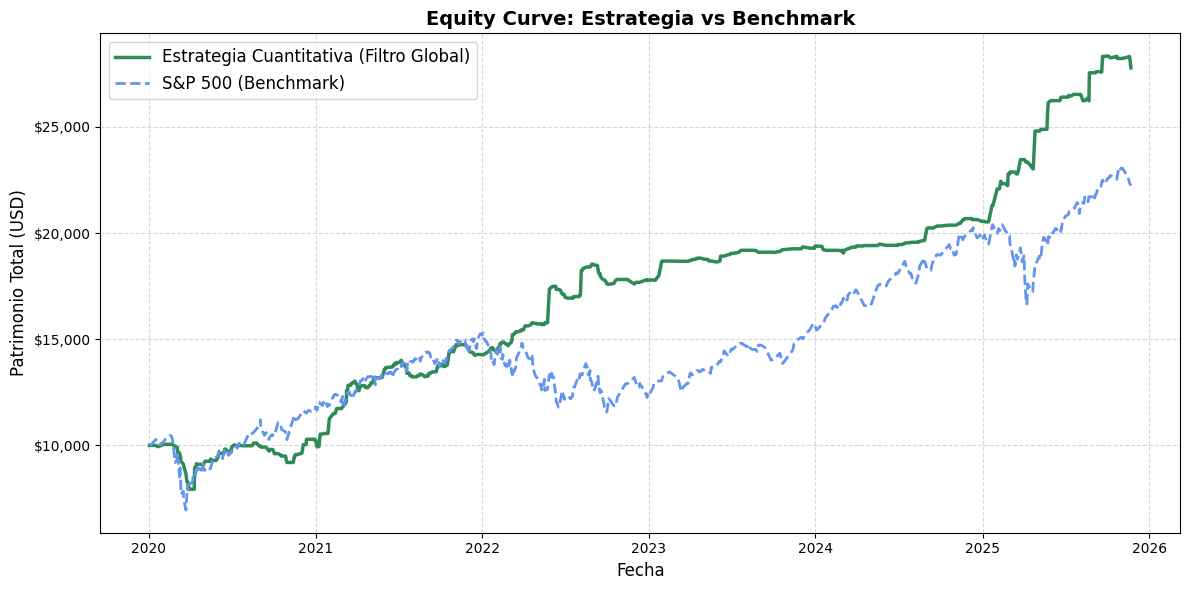

========== MÉTRICAS DE RENDIMIENTO ACUMULADO ==========
Período evaluado: Desde 2020-01-03 hasta el último registro
Capital Final Estrategia : $27,783.75
Capital Final S&P 500    : $22,240.65
Exceso de Retorno (Alpha): $5,543.10


In [11]:
# Simulador de cartera continuo y generación de curva de capital (Equity Curve)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Configuración del backtest
CAPITAL_INICIAL = 10000.0
TAMANO_POSICION = 750.0

ops = ops_global[ops_global['Buy_Date'].dt.year >= 2020].copy()
ops = ops.sort_values('Buy_Date')

cash = CAPITAL_INICIAL
operaciones_abiertas = []
historial_curva = []

# Inicialización del benchmark (S&P 500 Buy & Hold)
fecha_inicio = ops['Buy_Date'].min()
precio_spy_inicio = get_price('SPY', fecha_inicio, 'forward')
acciones_spy_benchmark = CAPITAL_INICIAL / precio_spy_inicio if pd.notna(precio_spy_inicio) else 0

# Generación de la línea temporal de eventos
fechas_eventos = sorted(list(set(ops['Buy_Date'].tolist() + ops['Sell_Date'].tolist())))

print("Calculando evolución diaria del portafolio...")

for fecha in fechas_eventos:
    # Liquidación de posiciones (Liberación de capital)
    ventas_hoy = [op for op in operaciones_abiertas if op['fecha_venta'] == fecha]
    operaciones_abiertas = [op for op in operaciones_abiertas if op['fecha_venta'] > fecha]
    
    for venta in ventas_hoy:
        cash += TAMANO_POSICION * (1 + venta['retorno'])
        
    # Ejecución de nuevas señales de compra
    compras_hoy = ops[ops['Buy_Date'] == fecha]
    for _, row in compras_hoy.iterrows():
        if cash >= TAMANO_POSICION:
            cash -= TAMANO_POSICION
            operaciones_abiertas.append({
                'fecha_venta': row['Sell_Date'],
                'retorno': row['Return_19d']
            })

    # Cálculo del NAV (Net Asset Value) diario
    valor_operaciones = len(operaciones_abiertas) * TAMANO_POSICION
    capital_total = cash + valor_operaciones
    
    # Valoración diaria del benchmark
    precio_spy_hoy = get_price('SPY', fecha, 'nearest')
    valor_spy = acciones_spy_benchmark * precio_spy_hoy if pd.notna(precio_spy_hoy) else np.nan
    
    historial_curva.append({
        'Fecha': fecha,
        'Estrategia_Global': capital_total,
        'SP500_Hold': valor_spy
    })

# Visualización de la Equity Curve
df_curva = pd.DataFrame(historial_curva).dropna()
df_curva.set_index('Fecha', inplace=True)

plt.figure(figsize=(12, 6))
plt.plot(df_curva.index, df_curva['Estrategia_Global'], label='Estrategia Cuantitativa (Filtro Global)', color='seagreen', linewidth=2.5)
plt.plot(df_curva.index, df_curva['SP500_Hold'], label='S&P 500 (Benchmark)', color='cornflowerblue', linewidth=2, linestyle='--')

plt.title('Equity Curve: Estrategia vs Benchmark', fontsize=14, fontweight='bold')
plt.xlabel('Fecha', fontsize=12)
plt.ylabel('Patrimonio Total (USD)', fontsize=12)
plt.legend(fontsize=12, loc='upper left')
plt.grid(True, linestyle='--', alpha=0.5)

formatter = plt.FuncFormatter(lambda x, loc: f"${x:,.0f}")
plt.gca().yaxis.set_major_formatter(formatter)

plt.tight_layout()
plt.show()

# Consolidado de rendimiento
print("========== MÉTRICAS DE RENDIMIENTO ACUMULADO ==========")
print(f"Período evaluado: Desde {fecha_inicio.strftime('%Y-%m-%d')} hasta el último registro")
print(f"Capital Final Estrategia : ${df_curva['Estrategia_Global'].iloc[-1]:,.2f}")
print(f"Capital Final S&P 500    : ${df_curva['SP500_Hold'].iloc[-1]:,.2f}")
print(f"Exceso de Retorno (Alpha): ${(df_curva['Estrategia_Global'].iloc[-1] - df_curva['SP500_Hold'].iloc[-1]):,.2f}")
print("=======================================================")